# Driver Risk Assessment Using a Bayesian Network



## 1. Import libraries

In [25]:
import sys
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    log_loss
)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

try:
    import pgmpy
    print("pgmpy:", pgmpy.__version__)
except ImportError:
    print("pgmpy is not installed. Run: %pip install pgmpy")


Python: 3.10.0rc2
NumPy: 2.0.2
Pandas: 2.2.3
pgmpy: 1.1.2


## 2. Load the dataset

The code first checks the Windows path supplied for this project. If the file is not found there (for example, when running outside your laptop), it asks you to upload the CSV.

In [26]:
from pathlib import Path

file_path = Path(r"C:\Users\rupes\SEM5\PROJECTS\probabilty\project\main\driver_risk_final_data1.csv")

if file_path.exists():
    df = pd.read_csv(file_path)
    print("Loaded:", file_path)
else:
    print("CSV was not found at the configured Windows path.")
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_names:
            raise FileNotFoundError("No CSV file was uploaded.")
        df = pd.read_csv(csv_names[0])
        print("Loaded uploaded file:", csv_names[0])
    except ImportError:
        from tkinter import Tk, filedialog
        root = Tk()
        root.withdraw()
        selected_file = filedialog.askopenfilename(
            title="Select driver_risk_demo_uncertain_labels.csv",
            filetypes=[("CSV files", "*.csv")]
        )
        root.destroy()
        if not selected_file:
            raise FileNotFoundError(
                "Select the CSV file or update file_path to its correct location."
            )
        df = pd.read_csv(selected_file)
        print("Loaded:", selected_file)

print("Dataset shape:", df.shape)
display(df.head())


Loaded: C:\Users\rupes\SEM5\PROJECTS\probabilty\project\main\driver_risk_final_data1.csv
Dataset shape: (6000, 6)


,video_id,DriverState,Weather,Traffic,Speed,Risk
0,video 0,SafeDriving,Rainy,Medium,Normal,Low
1,video 1,Yawn,Rainy,Heavy,High,High
2,video 2,Distracted,Clear,Heavy,Normal,Medium
3,video 3,Drinking,Rainy,Low,Normal,Medium
4,video 0,SleepyDriving,Clear,Heavy,High,High


## 3. Understand and validate the data

Check the column names, data types, missing values, duplicates, and category distributions. Duplicate feature rows are not automatically errors: multiple observations can share the same feature values and may have different labels in an uncertain-label dataset.

Columns: ['video_id', 'DriverState', 'Weather', 'Traffic', 'Speed', 'Risk']
\nData types:


,Data type
video_id,object
DriverState,object
Weather,object
Traffic,object
Speed,object
Risk,object


\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   video_id     6000 non-null   object
 1   DriverState  6000 non-null   object
 2   Weather      6000 non-null   object
 3   Traffic      6000 non-null   object
 4   Speed        6000 non-null   object
 5   Risk         6000 non-null   object
dtypes: object(6)
memory usage: 281.4+ KB
\nMissing values per column:


,Missing values
video_id,0
DriverState,0
Weather,0
Traffic,0
Speed,0
Risk,0


\nExact duplicate rows: 5320
\nFirst five records:


,video_id,DriverState,Weather,Traffic,Speed,Risk
0,video 0,SafeDriving,Rainy,Medium,Normal,Low
1,video 1,Yawn,Rainy,Heavy,High,High
2,video 2,Distracted,Clear,Heavy,Normal,Medium
3,video 3,Drinking,Rainy,Low,Normal,Medium
4,video 0,SleepyDriving,Clear,Heavy,High,High


\nRisk distribution:


,Count
Risk,
High,2948
Medium,2255
Low,797


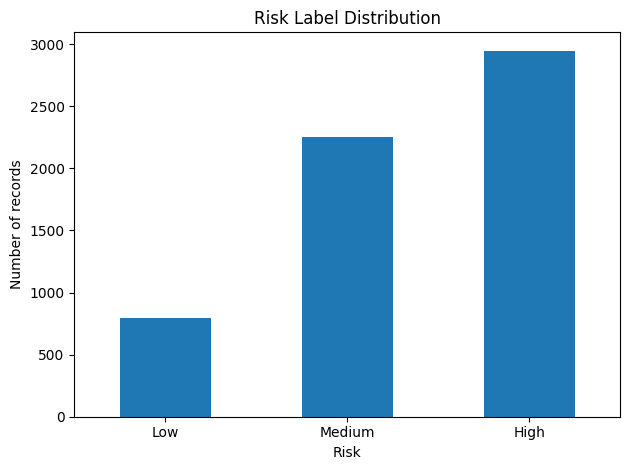

In [27]:
print("Columns:", df.columns.tolist())
print("\\nData types:")
display(df.dtypes.to_frame("Data type"))

print("\\nDataset information:")
df.info()

print("\\nMissing values per column:")
display(df.isna().sum().to_frame("Missing values"))

print("\\nExact duplicate rows:", int(df.duplicated().sum()))

print("\\nFirst five records:")
display(df.head())

print("\\nRisk distribution:")
display(df["Risk"].value_counts(dropna=False).to_frame("Count"))

ax = df["Risk"].value_counts().reindex(["Low", "Medium", "High"]).plot(
    kind="bar", title="Risk Label Distribution", rot=0
)
ax.set_xlabel("Risk")
ax.set_ylabel("Number of records")
plt.tight_layout()
plt.show()


## 4. Prepare model data

The model uses four evidence features and one target. `video_id` is an identifier, so it is not used as a predictor. Missing rows in required columns are removed, and categorical values are converted to strings for pgmpy.

In [28]:
features = ["DriverState", "Weather", "Traffic", "Speed"]
target = "Risk"
required_columns = features + [target]

missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Required columns missing from CSV: {missing_columns}")

data = df[required_columns].copy()
rows_before = len(data)
data = data.dropna(subset=required_columns).copy()
print("Rows before required-field cleanup:", rows_before)
print("Rows after required-field cleanup:", len(data))

for col in required_columns:
    data[col] = data[col].astype(str).str.strip()

print("\\nUnique categories:")
for col in required_columns:
    print(f"{col}: {sorted(data[col].unique().tolist())}")

print("\\nFinal modelling data shape:", data.shape)
display(data.head())


Rows before required-field cleanup: 6000
Rows after required-field cleanup: 6000
\nUnique categories:
DriverState: ['DangerousDriving', 'Distracted', 'Drinking', 'SafeDriving', 'SleepyDriving', 'Yawn']
Weather: ['Clear', 'Foggy', 'Rainy']
Traffic: ['Heavy', 'Low', 'Medium']
Speed: ['High', 'Normal']
Risk: ['High', 'Low', 'Medium']
\nFinal modelling data shape: (6000, 5)


,DriverState,Weather,Traffic,Speed,Risk
0,SafeDriving,Rainy,Medium,Normal,Low
1,Yawn,Rainy,Heavy,High,High
2,Distracted,Clear,Heavy,Normal,Medium
3,Drinking,Rainy,Low,Normal,Medium
4,SleepyDriving,Clear,Heavy,High,High


## 5. Split into training and test sets

The test set is held out from parameter fitting. Stratification keeps the overall risk-class proportions approximately similar between the two sets.

In [29]:
train_data, test_data = train_test_split(
    data,
    test_size=0.20,
    random_state=42,
    stratify=data[target]
)

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

print("\\nTraining risk distribution:")
display(train_data[target].value_counts(normalize=True).mul(100).round(2).to_frame("Percent"))

print("\\nTesting risk distribution:")
display(test_data[target].value_counts(normalize=True).mul(100).round(2).to_frame("Percent"))


Training rows: 4800
Testing rows: 1200
\nTraining risk distribution:


,Percent
Risk,
High,49.12
Medium,37.58
Low,13.29


\nTesting risk distribution:


,Percent
Risk,
High,49.17
Medium,37.58
Low,13.25


## 6. Define the Bayesian Network

The graph below expresses the project's assumed dependencies. Weather and traffic may influence speed and risk; driver state may influence speed and risk; and speed contributes to the risk estimate. These are modelling assumptions, not proof of causality.

Is the graph a directed acyclic graph (DAG)? True


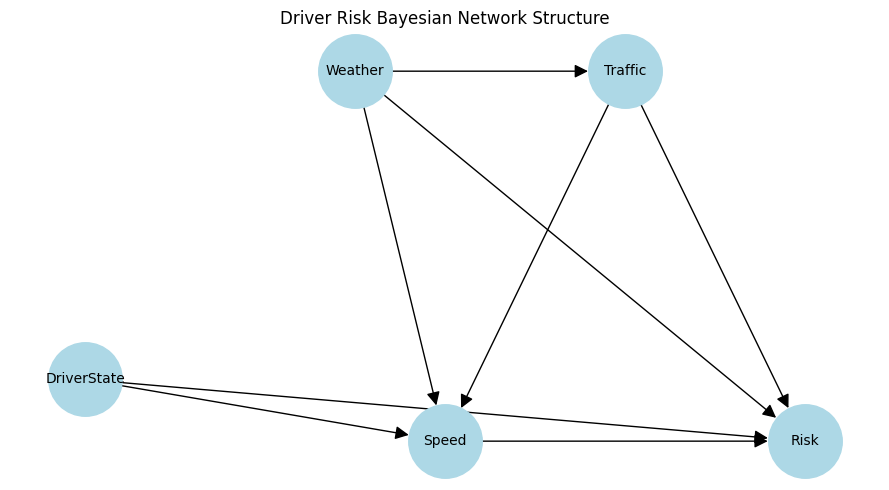

In [30]:
from pgmpy.models import DiscreteBayesianNetwork
import networkx as nx

edges = [
    ("Weather", "Traffic"),
    ("Weather", "Speed"),
    ("Traffic", "Speed"),
    ("DriverState", "Speed"),
    ("DriverState", "Risk"),
    ("Weather", "Risk"),
    ("Traffic", "Risk"),
    ("Speed", "Risk")
]

model = DiscreteBayesianNetwork(edges)

print("Is the graph a directed acyclic graph (DAG)?",
      nx.is_directed_acyclic_graph(model))

plt.figure(figsize=(9, 5))
pos = {
    "DriverState": (0, 1),
    "Weather": (1.5, 2),
    "Traffic": (3, 2),
    "Speed": (2, 0.8),
    "Risk": (4, 0.8)
}
nx.draw_networkx(
    model, pos=pos, with_labels=True, node_size=2800,
    node_color="lightblue", arrows=True, font_size=10,
    arrowsize=20
)
plt.title("Driver Risk Bayesian Network Structure")
plt.axis("off")
plt.tight_layout()
plt.show()


## 7. Learn the conditional probability tables (CPTs)

In [31]:
from pgmpy.estimators import BayesianEstimator

state_names = {
    col: sorted(data[col].unique().tolist())
    for col in required_columns
}

estimator = BayesianEstimator(
    model,
    train_data[required_columns],
    state_names=state_names
)
cpds = estimator.get_parameters(
    prior_type="BDeu",
    equivalent_sample_size=10
)
model.add_cpds(*cpds)

print("Model check passed:", model.check_model())
print("\\nLearned CPTs:")
for cpd in model.get_cpds():
    print("\\n", cpd)


Model check passed: True
\nLearned CPTs:
\n +----------------+----------+
| Weather(Clear) | 0.333125 |
+----------------+----------+
| Weather(Foggy) | 0.330215 |
+----------------+----------+
| Weather(Rainy) | 0.33666  |
+----------------+----------+
\n +-----------------+-----+--------------------+
| Weather         | ... | Weather(Rainy)     |
+-----------------+-----+--------------------+
| Traffic(Heavy)  | ... | 0.3372444078495952 |
+-----------------+-----+--------------------+
| Traffic(Low)    | ... | 0.3285988747083848 |
+-----------------+-----+--------------------+
| Traffic(Medium) | ... | 0.33415671744202   |
+-----------------+-----+--------------------+
\n +---------------+-----+-------------------+
| DriverState   | ... | DriverState(Yawn) |
+---------------+-----+-------------------+
| Traffic       | ... | Traffic(Medium)   |
+---------------+-----+-------------------+
| Weather       | ... | Weather(Rainy)    |
+---------------+-----+-------------------+
| Speed(H

## 8. Perform probabilistic inference

For an example scenario, query the posterior probability of each risk category given the four observed features. Change the evidence values to test other scenarios; use category values printed in Section 4.

Evidence: {'DriverState': 'DangerousDriving', 'Weather': 'Rainy', 'Traffic': 'Heavy', 'Speed': 'High'}


,Probability
Low,0.000629
Medium,0.082107
High,0.917264


Most probable risk: High
Posterior probabilities sum to: 1.0


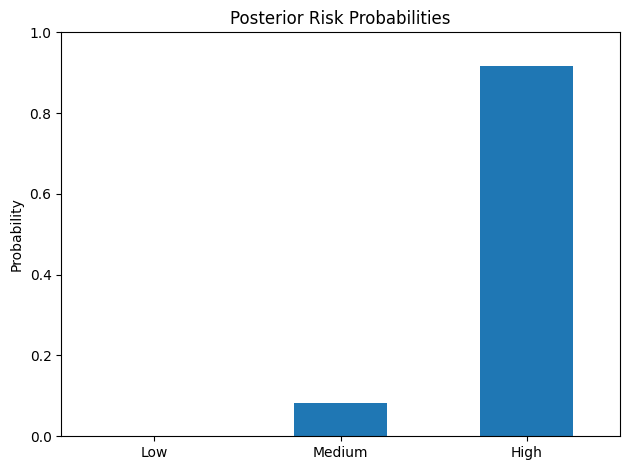

In [32]:
from pgmpy.inference import VariableElimination

inference = VariableElimination(model)

example_evidence = {
    "DriverState": "DangerousDriving",
    "Weather": "Rainy",
    "Traffic": "Heavy",
    "Speed": "High"
}

# Validate evidence categories before querying.
for variable, value in example_evidence.items():
    if value not in state_names[variable]:
        raise ValueError(
            f"{value!r} is not a known value for {variable}. "
            f"Choose from {state_names[variable]}"
        )

result = inference.query(
    variables=[target],
    evidence=example_evidence,
    show_progress=False
)

posterior = pd.Series(
    result.values,
    index=result.state_names[target],
    name="Probability"
).reindex(["Low", "Medium", "High"])

print("Evidence:", example_evidence)
display(posterior.to_frame())
print("Most probable risk:", posterior.idxmax())
print("Posterior probabilities sum to:", round(float(posterior.sum()), 6))

posterior.plot(kind="bar", ylim=(0, 1), rot=0, title="Posterior Risk Probabilities")
plt.ylabel("Probability")
plt.tight_layout()
plt.show()


## 9. Evaluate

Test accuracy: 94.33%
\nClassification report:
              precision    recall  f1-score   support

         Low       0.94      0.96      0.95       159
      Medium       0.96      0.89      0.92       451
        High       0.94      0.98      0.96       590

    accuracy                           0.94      1200
   macro avg       0.94      0.94      0.94      1200
weighted avg       0.94      0.94      0.94      1200

Multiclass log loss: 5.5851


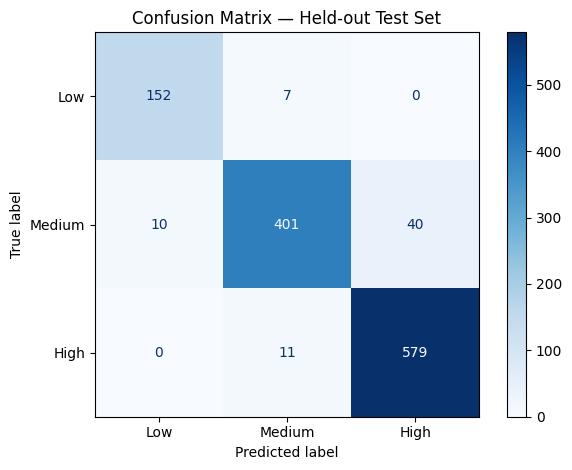

In [33]:
risk_classes = ["Low", "Medium", "High"]
probability_cache = {}

unique_evidence_rows = test_data[features].drop_duplicates()

for row in unique_evidence_rows.itertuples(index=False, name=None):
    evidence = dict(zip(features, row))
    query_result = inference.query(
        variables=[target],
        evidence=evidence,
        show_progress=False
    )
    probability_cache[tuple(row)] = dict(
        zip(query_result.state_names[target], query_result.values)
    )

y_true = test_data[target].tolist()
y_pred = []
y_prob = []

for row in test_data[features].itertuples(index=False, name=None):
    probabilities = probability_cache[tuple(row)]
    y_pred.append(max(probabilities, key=probabilities.get))
    y_prob.append([probabilities.get(label, 0.0) for label in risk_classes])

accuracy = accuracy_score(y_true, y_pred)
print(f"Test accuracy: {accuracy * 100:.2f}%")
print("\\nClassification report:")
print(classification_report(
    y_true, y_pred, labels=risk_classes, zero_division=0
))

try:
    print("Multiclass log loss:",
          round(log_loss(y_true, y_prob, labels=risk_classes), 4))
except ValueError as exc:
    print("Log loss could not be calculated:", exc)

cm = confusion_matrix(y_true, y_pred, labels=risk_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=risk_classes)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Held-out Test Set")
plt.tight_layout()
plt.show()


## 10. Inspect individual test predictions

Review a sample of predictions, including the actual label and the model's posterior probability for the predicted class.

In [34]:
evaluation_df = test_data[features].copy().reset_index(drop=True)
evaluation_df["ActualRisk"] = y_true
evaluation_df["PredictedRisk"] = y_pred
evaluation_df["Correct"] = evaluation_df["ActualRisk"] == evaluation_df["PredictedRisk"]
evaluation_df["PredictedClassProbability"] = [
    max(probability_cache[tuple(row)].values())
    for row in test_data[features].itertuples(index=False, name=None)
]

display(evaluation_df.head(20))
print("Correct predictions:", int(evaluation_df["Correct"].sum()))
print("Incorrect predictions:", int((~evaluation_df["Correct"]).sum()))


,DriverState,Weather,Traffic,Speed,ActualRisk,PredictedRisk,Correct,PredictedClassProbability
0,Drinking,Rainy,Medium,Normal,High,High,True,0.957130
1,SleepyDriving,Foggy,Heavy,Normal,High,High,True,0.898691
2,Drinking,Clear,Medium,Normal,Medium,Medium,True,0.928950
3,Distracted,Foggy,Low,High,High,High,True,0.954278
4,SleepyDriving,Clear,Low,High,Medium,Medium,True,0.972128
5,DangerousDriving,Foggy,Low,Normal,Medium,Medium,True,0.952156
6,DangerousDriving,Rainy,Medium,Normal,High,High,True,0.930561
7,SafeDriving,Foggy,Medium,High,Medium,Medium,True,0.975920
8,Distracted,Rainy,Medium,High,High,High,True,0.933574
9,DangerousDriving,Foggy,Low,Normal,Medium,Medium,True,0.952156


Correct predictions: 1132
Incorrect predictions: 68


## 11. Make a prediction for a new scenario

Edit the four values in `new_scenario` to test a scenario. The values must match categories present in the dataset.

In [35]:
new_scenario = {
    "DriverState": "Distracted",
    "Weather": "Foggy",
    "Traffic": "Heavy",
    "Speed": "High"
}

for variable, value in new_scenario.items():
    if value not in state_names[variable]:
        raise ValueError(
            f"Unknown {variable}={value!r}. Available values: {state_names[variable]}"
        )

scenario_result = inference.query(
    variables=[target],
    evidence=new_scenario,
    show_progress=False
)

scenario_probabilities = pd.Series(
    scenario_result.values,
    index=scenario_result.state_names[target],
    name="Probability"
).reindex(risk_classes)

print("Scenario:", new_scenario)
print("Predicted risk:", scenario_probabilities.idxmax())
display(scenario_probabilities.to_frame())


Scenario: {'DriverState': 'Distracted', 'Weather': 'Foggy', 'Traffic': 'Heavy', 'Speed': 'High'}
Predicted risk: High


,Probability
Low,0.000716
Medium,0.047128
High,0.952156


## 12. Save model artifacts

Save the learned Bayesian Network and a CSV of test predictions in the current working directory. The saved model can be loaded later with pgmpy's `BIFReader`. Keep the dataset and the saved model together when sharing the project.

In [36]:
from pathlib import Path

output_dir = Path.cwd()
model_file = output_dir / "driver_risk_bayesian_network.bif"
predictions_file = output_dir / "driver_risk_test_predictions.csv"

model.save(str(model_file), filetype="bif")
evaluation_df.to_csv(predictions_file, index=False)

print("Saved model:", model_file.resolve())
print("Saved predictions:", predictions_file.resolve())


Saved model: C:\Users\rupes\SEM5\PROJECTS\probabilty\project\main\driver_risk_bayesian_network.bif
Saved predictions: C:\Users\rupes\SEM5\PROJECTS\probabilty\project\main\driver_risk_test_predictions.csv
